# Maine towns — exploratory data analysis

Data: U.S. Census Bureau, American Community Survey 2020–2024 5-year estimates for every Maine county
subdivision (`data/gov/acs5_maine_towns.csv`, downloaded by `market_lab/acs_towns.py` with checksums),
plus the FHFA house price index and BLS unemployment already used by the website.

Questions: What do Maine towns look like? What is related to home values? What cleaning does the data need?

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px, plotly.io as pio
pio.renderers.default = "notebook_connected"   # loads plotly.js from a CDN instead of embedding 3 MB
sns.set_theme(style="whitegrid")
import sys; sys.path.insert(0, "..")
from market_lab import data

raw = data.load_raw()
raw.shape, raw.columns.tolist()

((529, 17),
 ['geo_id',
  'town',
  'county',
  'population',
  'population_moe',
  'median_household_income',
  'median_household_income_moe',
  'median_home_value',
  'median_home_value_moe',
  'median_gross_rent',
  'median_gross_rent_moe',
  'occupied_units',
  'owner_occupied_units',
  'housing_units',
  'vacant_units',
  'median_age',
  'median_year_built'])

## 1. Raw data quality
Census marks unavailable estimates with large negative codes. Count them per column before cleaning.

In [2]:
numeric = raw.columns.difference(["geo_id", "town", "county"])
(raw[numeric] < 0).sum().sort_values(ascending=False).to_frame("census 'not available' codes")

,census 'not available' codes
median_gross_rent,168
median_gross_rent_moe,168
median_household_income,33
median_household_income_moe,33
median_home_value,31
median_home_value_moe,31
median_age,14
median_year_built,7
housing_units,0
occupied_units,0


In [3]:
ds = data.load()
pd.Series(ds.report).to_frame("count")

,count
raw_rows,529
census_codes_replaced,485
tiny_places_dropped,53
missing_target,5
unreliable_target,14
clean_towns,476
model_towns,457
model_rows_with_missing_features,105


Cleaning rules applied (from `market_lab/data.py`):

In [4]:
pd.Series(data.CLEANING_RULES).to_frame("rule")

,rule
census_codes,Negative values are Census codes for 'not avai...
tiny_places,Places with fewer than 100 residents (mostly u...
unreliable_target,Median home value with a coefficient of variat...
missing_target,No published median home value → excluded from...


## 2. Missing values after cleaning
Median rent is the column most often unpublished (small towns). Models impute it inside cross-validation.

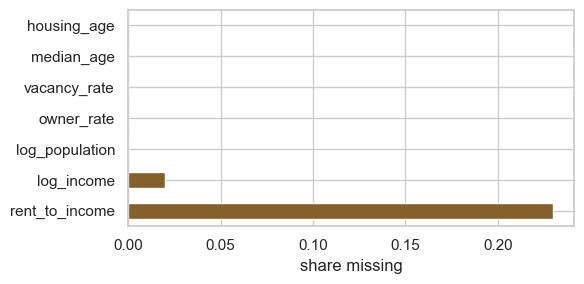

In [5]:
missing = ds.model[data.FEATURES].isna().mean().sort_values(ascending=False)
ax = missing.plot.barh(figsize=(6, 3), color="#86602a"); ax.set_xlabel("share missing"); plt.tight_layout()

## 3. Distributions
Home values are right-skewed, so models predict the log.

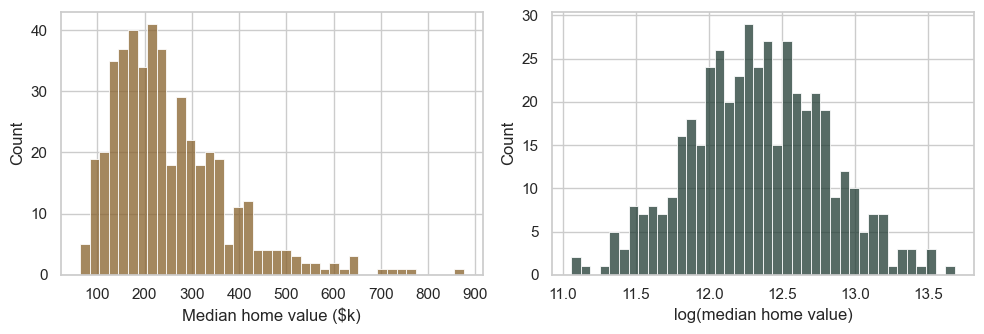

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(ds.model["median_home_value"] / 1000, bins=40, ax=axes[0], color="#86602a"); axes[0].set_xlabel("Median home value ($k)")
sns.histplot(ds.model["log_home_value"], bins=40, ax=axes[1], color="#1f3a32"); axes[1].set_xlabel("log(median home value)")
plt.tight_layout()

In [7]:
ds.model[data.FEATURES + ["median_home_value"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
log_population,457.0,7.247,1.210,4.615,6.409,7.210,8.050,11.140
log_income,448.0,11.126,0.276,10.112,10.949,11.107,11.332,12.066
rent_to_income,352.0,0.180,0.051,0.054,0.147,0.178,0.207,0.390
owner_rate,457.0,0.836,0.106,0.466,0.792,0.855,0.911,1.000
vacancy_rate,457.0,0.270,0.182,0.008,0.119,0.229,0.387,0.945
median_age,457.0,48.317,8.000,19.300,42.800,48.100,53.400,70.000
housing_age,457.0,45.851,11.219,24.000,38.000,44.000,50.000,86.000
median_home_value,457.0,252389.716,124363.507,63300.000,164400.000,222900.000,311600.000,875700.000


## 4. Relationships
Correlation (Spearman: rank-based, robust to skew) between the engineered features and the target.

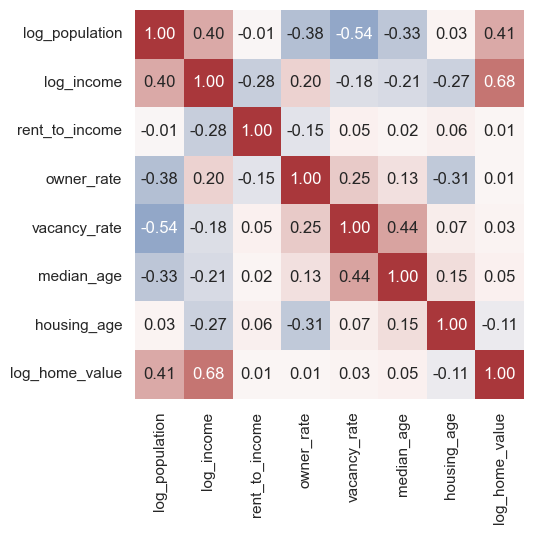

In [8]:
corr = ds.model[data.FEATURES + [data.TARGET]].corr(method="spearman")
plt.figure(figsize=(7, 5.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, cbar=False); plt.tight_layout()

Income is the strongest single correlate. The seasonal-home share (vacancy) matters in Maine: ski and lake towns have high values with many homes empty most of the year.

In [9]:
fig = px.scatter(ds.model, x="median_household_income", y="median_home_value", color="vacancy_rate", hover_name="short_name",
                 hover_data=["county", "population"], log_x=True, log_y=True, color_continuous_scale="Viridis",
                 labels={"median_household_income": "Median household income", "median_home_value": "Median home value", "vacancy_rate": "Seasonal/vacant share"},
                 title="Maine towns: income vs home value (interactive)")
fig.update_layout(height=480); fig

In [10]:
top = ds.towns.dropna(subset=["median_home_value"]).nlargest(8, "vacancy_rate")[["short_name", "county", "vacancy_rate", "median_home_value", "population"]]
top.style.format({"vacancy_rate": "{:.0%}", "median_home_value": "${:,.0f}", "population": "{:,.0f}"})

,short_name,county,vacancy_rate,median_home_value,population
238,Newry,Oxford,94%,"$307,700",177
102,Carrabassett Valley,Franklin,84%,"$343,600",637
322,Lake View,Piscataquis,81%,"$351,000",181
52,Orient,Aroostook,78%,"$548,600",137
130,Cranberry Isles,Hancock,77%,"$439,100",196
367,Northeast Somerset,Somerset,77%,"$341,300",516
317,Bowerbank,Piscataquis,76%,"$199,500",211
87,Long Island,Cumberland,75%,"$551,100",249


## 5. Our towns in context

In [11]:
ours = ["Waterville", "Augusta", "Winslow", "Oakland", "Sidney", "Belgrade", "Fairfield"]
view = ds.towns[ds.towns.short_name.isin(ours)].set_index("short_name")
view["home value percentile (Maine towns)"] = view["median_home_value"].apply(lambda v: (ds.towns["median_home_value"] < v).mean())
view[["county", "median_home_value", "median_household_income", "owner_rate", "home value percentile (Maine towns)"]].style.format(
    {"median_home_value": "${:,.0f}", "median_household_income": "${:,.0f}", "owner_rate": "{:.0%}", "home value percentile (Maine towns)": "{:.0%}"})

,county,median_home_value,median_household_income,owner_rate,home value percentile (Maine towns)
short_name,,,,,
Augusta,Kennebec,"$201,000","$47,979",54%,41%
Belgrade,Kennebec,"$312,200","$88,338",94%,75%
Oakland,Kennebec,"$236,000","$77,813",78%,55%
Sidney,Kennebec,"$336,200","$83,488",89%,79%
Waterville,Kennebec,"$184,600","$53,580",49%,34%
Winslow,Kennebec,"$225,300","$70,917",76%,51%
Fairfield,Somerset,"$164,300","$64,101",79%,25%


## 6. Prices over time (FHFA) and the labour market (BLS)

geo,kennebec,maine,somerset
year,,,
2020,5.2,4.7,6.1
2021,16.1,13.7,13.2
2022,16.0,16.7,17.0
2023,9.4,11.0,12.7
2024,6.9,5.8,6.1
2025,5.0,4.6,9.2


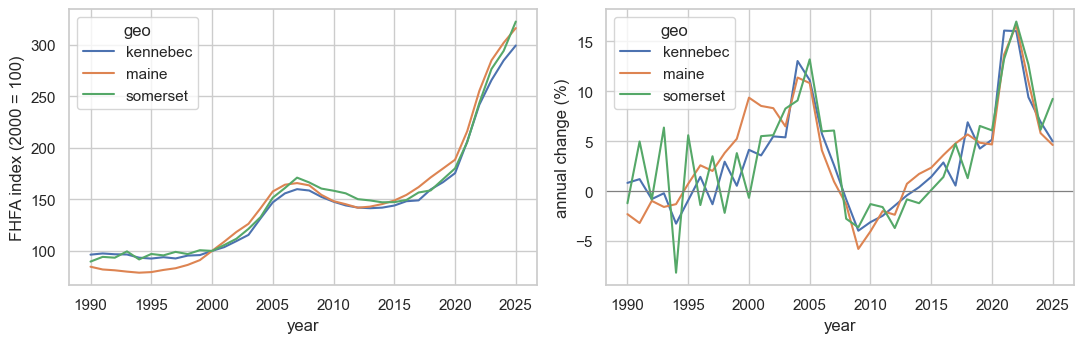

In [12]:
hpi = data.load_hpi()
growth = np.log(hpi).diff() * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
hpi[hpi.index >= 1990].plot(ax=axes[0]); axes[0].set_ylabel("FHFA index (2000 = 100)")
growth[growth.index >= 1990].plot(ax=axes[1]); axes[1].axhline(0, color="grey", lw=0.8); axes[1].set_ylabel("annual change (%)")
plt.tight_layout()
growth.tail(6).round(1)

period,1,2,3,4,5,6,7,8,9,10,11,12
area,,,,,,,,,,,,
kennebec,3.60,3.48,3.24,2.84,2.85,2.71,2.75,2.71,2.61,2.63,2.94,2.87
maine,3.16,3.08,3.02,2.98,2.98,2.99,3.01,3.04,3.04,3.05,3.07,3.06
somerset,5.58,5.52,4.95,4.51,4.09,3.56,3.90,3.56,3.49,3.50,4.00,4.31
us,4.44,4.35,4.05,3.61,3.71,4.15,4.22,4.14,3.76,3.60,3.70,3.67


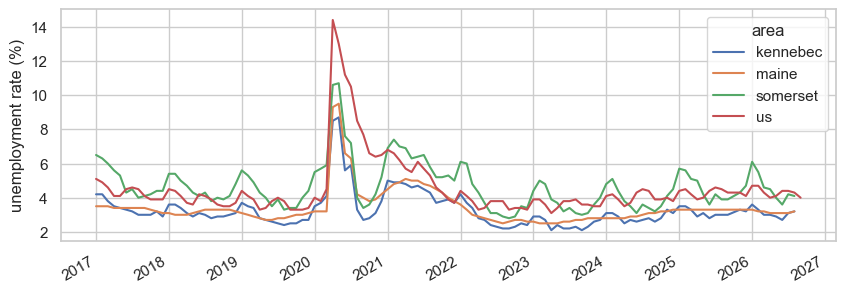

In [13]:
bls = pd.read_csv(data.DATA / "bls_laus.csv", parse_dates=["period"])
bls["area"] = bls["series_id"].str.split(":").str[-1]
wide = bls.pivot(index="period", columns="area", values="value")
ax = wide.plot(figsize=(10, 3.4)); ax.set_ylabel("unemployment rate (%)"); ax.set_xlabel("")
# Average by calendar month, leaving out 2020–21 (the COVID spike would dominate April–May).
# The statewide series (LASST…) is seasonally adjusted by BLS, so it's flat by design; the county
# and U.S. series are not adjusted and show the seasonal pattern.
normal = wide[~wide.index.year.isin([2020, 2021])]
normal.groupby(normal.index.month).mean().round(2).T

## Findings

- **Income explains most of the difference in home values between towns**; county (region) and the share of seasonal homes come next.
- **Seasonal-home towns are a distinct group**: very high "vacancy" with high values (ski and lake towns).
- **Data quality**: 53 tiny places dropped, 19 towns excluded from models (no published value or too uncertain), rent missing for ~23% of model towns — imputed inside cross-validation only.
- **Prices**: the FHFA index more than doubled from 2015 to 2025 (×2.1 Kennebec, ×2.2 Somerset); growth slowed after the 2021–22 peak (16–17% a year), though Somerset rose 9% in 2025.
- **County unemployment is seasonal**: outside 2020–21, Somerset averages ~5.6% in January vs ~3.5% in September, so compare the same month across years. (The statewide series is seasonally adjusted by BLS, so it doesn't show this.)

Next: `02_models.ipynb` (supervised models, clustering, forecasting).